# Chains


### why and what (chains)

when we create any llm application we follow some series of steps like
1. we create a prompt
2. we send prompt to llm
3. llm proccesses it and product output for user

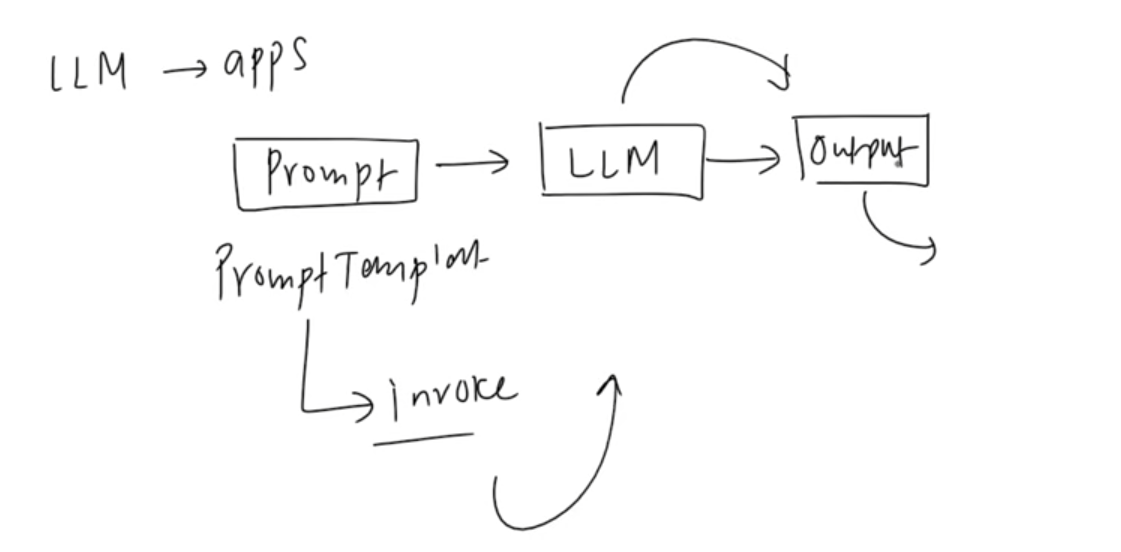

till now we have done many things manually
1. we create prompts using prompt template then take input from user with invoke
2. prompt are send to llm then llm process the prompts and excute with invoke 
3. if parsing is required then we use different output parsers

so in complex applications it is very difficult to do each and every task manually so we needed chains

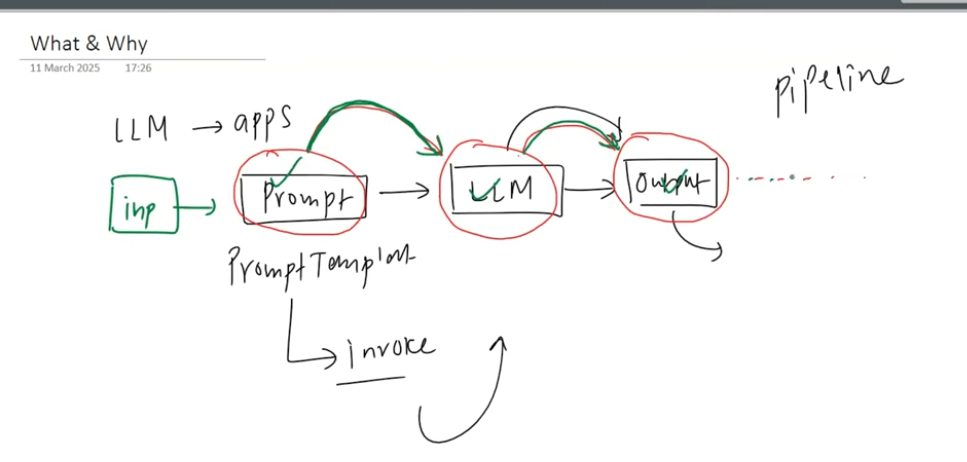

with help of chains we can create pipilines in which we can perform all our actions we only have to give input for our first step then output of first step will be input for second step and output of second step will be input for thired step and so on 

types of chain we will learn
1. sequence chain
2. parellel processing
3. conditional chain

## Simple chain


In [3]:
from langchain_ollama import ChatOllama
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser
model=ChatOllama(
    model='llama3.2:1b',
    temperature=0.7
)
template=PromptTemplate(
    template='Write 5 facts about {topic}',
    input_variables=['topic']
)
parser=StrOutputParser()

chain=template | model | parser
result=chain.invoke({'topic':'cricket'})
print(result)

Here are five facts about cricket:

1. Cricket is one of the oldest sports in the world, with a history dating back over 2,000 years. The game originated in England in the 16th century and was initially played with a flat bat and a hard ball.

2. The first recorded cricket match took place in 1598, when an English team played a match against a team from Hertfordshire. The game was initially played with rules that are still in use today, and it was considered a relatively simple game compared to modern-day cricket.

3. Cricket is played by over 2.5 million players worldwide, with the most popular versions being Test cricket, One-Day Internationals (ODIs), and Twenty20 (T20) cricket. The game is also popular in the Indian subcontinent, where it is known as "Test cricket" or "first-class" cricket.

4. The longest match in cricket history was played between Australia and England in 1939, which lasted for 7 days and 6 days, respectively. The match was played in Australia, and it was known a

In [4]:
chain.get_graph().print_ascii()

     +-------------+       
     | PromptInput |       
     +-------------+       
            *              
            *              
            *              
    +----------------+     
    | PromptTemplate |     
    +----------------+     
            *              
            *              
            *              
      +------------+       
      | ChatOllama |       
      +------------+       
            *              
            *              
            *              
   +-----------------+     
   | StrOutputParser |     
   +-----------------+     
            *              
            *              
            *              
+-----------------------+  
| StrOutputParserOutput |  
+-----------------------+  


## Sequential Chain

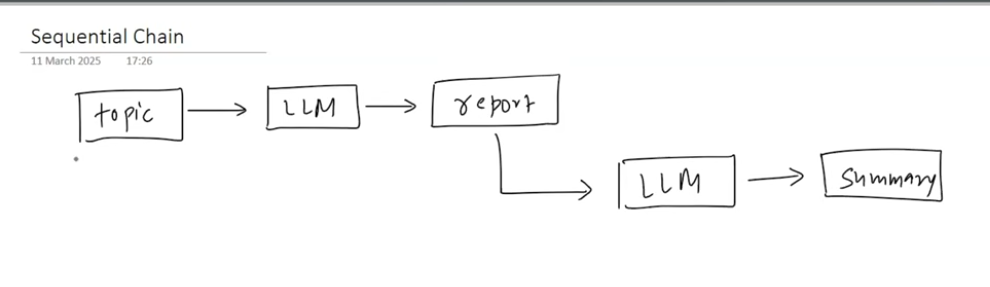

In [ ]:
from langchain_ollama import ChatOllama
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser
model=ChatOllama(
    model='llama3.2:1b',
    temperature=0.7
)

prompt1=PromptTemplate(
    template='write detailed report about {topic}',
    input_variables=['topic']
)

prompt2=PromptTemplate(
    template='write 5 important points about \n {text}',
    input_variables=['text']

)

parser=StrOutputParser()
chain=prompt1 | model | parser | prompt2 | model | parser
result=chain.invoke({'topic':'Unemployment in india'})
print(result)

# without chains
# p1=prompt1.invoke({'topic':'Unemployment in india'})
# result1=model.invoke(p1)
# data=parser.parse(result1.content)
# p2=prompt2.invoke({'text':'data'})
# result2=model.invoke(p2)
# print(result2.content)



Here are five important points about data:

1. **Data is a fundamental resource**: Data is a vital input for decision-making, innovation, and problem-solving in various industries, including business, healthcare, finance, and government. It is essential to understand the value and limitations of data to make informed decisions.

2. **Data quality is crucial**: The quality of data can significantly impact its usefulness and reliability. Poor data quality can lead to inaccurate or misleading results, which can have serious consequences. Ensuring the accuracy, completeness, and consistency of data is crucial to maintain its integrity.

3. **Data visualization is essential**: Data visualization is the process of presenting data in a clear and concise manner to facilitate understanding and interpretation. Effective data visualization can help identify trends, patterns, and correlations, making it easier to make informed decisions.

4. **Data security is paramount**: Data security is a criti

In [13]:
chain.get_graph().print_ascii()

     +-------------+       
     | PromptInput |       
     +-------------+       
            *              
            *              
            *              
    +----------------+     
    | PromptTemplate |     
    +----------------+     
            *              
            *              
            *              
      +------------+       
      | ChatOllama |       
      +------------+       
            *              
            *              
            *              
   +-----------------+     
   | StrOutputParser |     
   +-----------------+     
            *              
            *              
            *              
+-----------------------+  
| StrOutputParserOutput |  
+-----------------------+  
            *              
            *              
            *              
    +----------------+     
    | PromptTemplate |     
    +----------------+     
            *              
            *              
            *       

## parellel chain

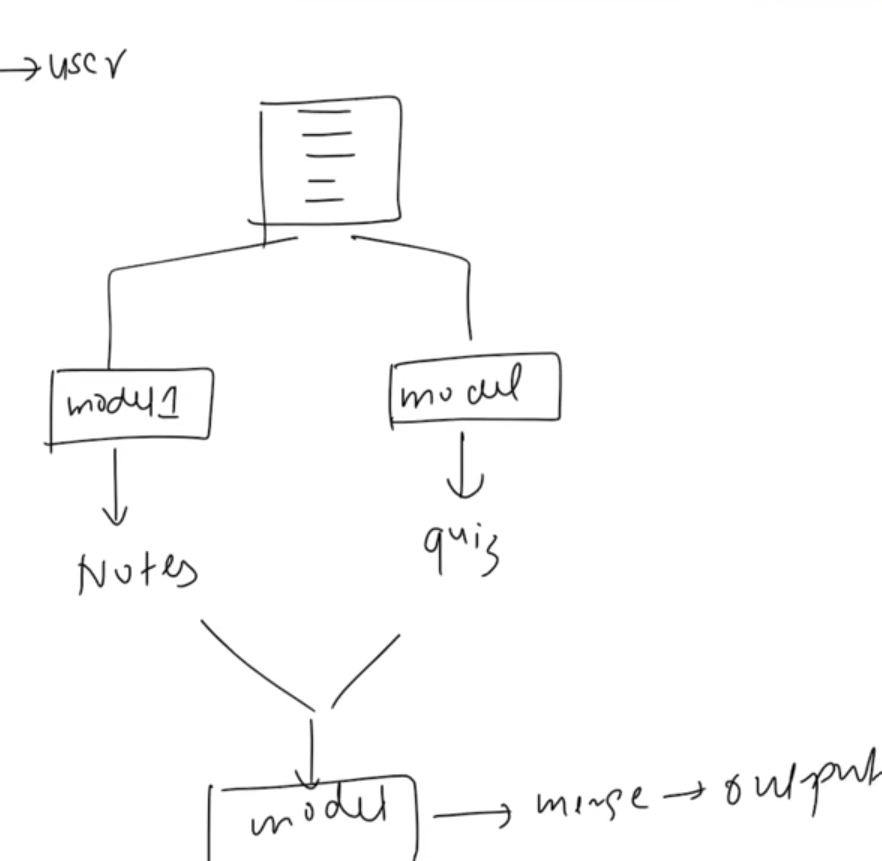

ek data aayega usko model 1 pass bhj denge to generate notes or parellely model 2 pass bhj denge to generete a quiz fir dono model ke result ko model 3 pass bhj denge to merge it

In [26]:
from langchain_ollama import ChatOllama
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableParallel# help to execute parellel chains
model1=ChatOllama(
    model='llama3.2:1b',
    temperature=0.7
)

model2=ChatOllama(
    model='llama3.2:1b',
    temperature=0.7
)

prompt1=PromptTemplate(
    template='Write a short and simple notes on {topic}',
    input_variables=['topic']
)

prompt2=PromptTemplate(
    template='Write 5 question answer on basic of data provided \n {topic}',
    input_variables=['topic']
)

prompt3=PromptTemplate(
    template='Merge the provided notes and question answers in single document \n notes->{notes} question answer->{quiz}',
    input_variables=['notes','quiz']
)

parser=StrOutputParser()

parellel_chain=RunnableParallel({
    'notes': prompt1 | model1 | parser,
    'quiz': prompt2 | model2 | parser
})

merge_chain=prompt3 | model1 | parser
chain=parellel_chain | merge_chain
text="""
Support vector machines (SVMs) are a set of supervised learning methods used for classification, regression and outliers detection.

The advantages of support vector machines are:

Effective in high dimensional spaces.
Still effective in cases where number of dimensions is greater than the number of samples.
Uses a subset of training points in the decision function (called support vectors), so it is also memory efficient.
Versatile: different Kernel functions can be specified for the decision function. Common kernels are provided, but it is also possible to specify custom kernels.

The disadvantages of support vector machines include:

If the number of features is much greater than the number of samples, avoid over-fitting in choosing Kernel functions and regularization term is crucial.
SVMs do not directly provide probability estimates, these are calculated using an expensive five-fold cross-validation (see Scores and probabilities, below).

The support vector machines in scikit-learn support both dense (numpy.ndarray and convertible to that by numpy.asarray) and sparse (any scipy.sparse) sample vectors as input. However, to use an SVM to make predictions for sparse data, it must have been fit on such data. For optimal performance, use C-ordered numpy.ndarray (dense) or scipy.sparse.csr_matrix (sparse) with dtype=float64.
"""

result=chain.invoke({'topic':text})
print(result)

Here are the merged notes and question answers in a single document:

**Support Vector Machines (SVMs)**

**Advantages:**

* Effective in high-dimensional spaces
* Suitable for large datasets with many features
* Memory-efficient due to using a subset of training points (support vectors)
* Versatile with customizable kernel functions

**Disadvantages:**

* May overfit if features are too many
* Requires regularization term for large datasets
* Does not provide probability estimates directly

**Notes on Support Vector Machines in scikit-learn:**

* Can handle both dense and sparse data inputs
* Must be fit on sparse data to optimize performance
* Use C-ordered numpy.ndarray (dense) or scipy.sparse.csr_matrix (sparse) for optimal performance

**1. What is the primary advantage of using support vector machines in high-dimensional spaces?**
A) They are less memory-efficient.
B) They are more prone to over-fitting.
C) They are effective in cases where the number of dimensions is greater tha

In [27]:
chain.get_graph().print_ascii()

            +---------------------------+            
            | Parallel<notes,quiz>Input |            
            +---------------------------+            
                 **               **                 
              ***                   ***              
            **                         **            
+----------------+                +----------------+ 
| PromptTemplate |                | PromptTemplate | 
+----------------+                +----------------+ 
          *                               *          
          *                               *          
          *                               *          
  +------------+                    +------------+   
  | ChatOllama |                    | ChatOllama |   
  +------------+                    +------------+   
          *                               *          
          *                               *          
          *                               *          
+-----------------+         

## Conditional Chain

In [1]:
from langchain_ollama import ChatOllama
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableParallel# help to execute parellel chains
from langchain_core.output_parsers import PydanticOutputParser
from langchain_core.runnables import RunnableParallel,RunnableBranch,RunnableLambda
from pydantic import Field,BaseModel
from typing import Literal
model=ChatOllama(
    model='llama3.2:1b',
    temperature=0.7
)

parser=StrOutputParser()

class Feedback(BaseModel):
    sentiment:Literal['positive','negative']

parser2=PydanticOutputParser(pydantic_object=Feedback)

prompt1=PromptTemplate(
    template='classify the sentiment of given feedback in positive or negative \n {feedback} \n {format_instruction}',
    input_variables=['feedback'],
    partial_variables={'format_instruction':parser2.get_format_instructions()}
    
)


prompt2 = PromptTemplate(
    template='Write an appropriate response to this positive feedback \n {feedback}',
    input_variables=['feedback']
)

prompt3 = PromptTemplate(
    template='Write an appropriate response to this negative feedback \n {feedback}',
    input_variables=['feedback']
)


classifier_chain=prompt1 | model | parser2
branch_chain = RunnableBranch(
    (lambda x: x.sentiment == 'positive', prompt2 | model | parser),
    (lambda x: x.sentiment == 'negative', prompt3 | model | parser),
    RunnableLambda(lambda x : "could not find sentiment")
)
chain = classifier_chain | branch_chain
result=chain.invoke({'feedback':'This is a wonderful smartphone'})
print(result)

I'm glad to hear that you're feeling positive about your experience. Thank you for sharing your feedback with me. I'm here to help and support you in any way I can. Is there anything else I can help with or any questions you have?


In [47]:
chain.get_graph().print_ascii()

    +-------------+      
    | PromptInput |      
    +-------------+      
            *            
            *            
            *            
   +----------------+    
   | PromptTemplate |    
   +----------------+    
            *            
            *            
            *            
     +------------+      
     | ChatOllama |      
     +------------+      
            *            
            *            
            *            
+----------------------+ 
| PydanticOutputParser | 
+----------------------+ 
            *            
            *            
            *            
       +--------+        
       | Branch |        
       +--------+        
            *            
            *            
            *            
    +--------------+     
    | BranchOutput |     
    +--------------+     
